# Sleep Quality

## Imports

In [1]:
import sys
import os
import pandas as pd
import numpy as np
from skfuzzy.control import Rule

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from preprocessor import clean_missing_values
from mamdani_engine import GenericMamdaniEngine
from evaluation import (evaluate_regression, plot_regression_results, plot_membership_functions, plot_control_surface, plot_data_distributions, plot_universe_percentiles)

## Data Preprocessing

In [2]:
# File paths
raw_path = '../data/raw/whoop_fitness_dataset_100k.csv'
processed_path = '../data/processed/whoop_clean.csv'

# Data Loading & Preprocessing using the general preprocessor
if not os.path.exists(processed_path):
    print("Loading raw data and applying general preprocessing...")
    df_raw = pd.read_csv(raw_path)
    selected_cols = ['hrv', 'day_strain', 'wake_ups', 'sleep_efficiency']
    df_subset = df_raw[selected_cols].copy()
    
    df_clean = clean_missing_values(df_subset, subset_columns=selected_cols)
    
    os.makedirs(os.path.dirname(processed_path), exist_ok=True)
    df_clean.to_csv(processed_path, index=False)
    print(f"Clean dataset saved to: {processed_path}")
else:
    print("Loading preprocessed dataset...")
    df_clean = pd.read_csv(processed_path)

print(f"Dataset shape: {df_clean.shape}")
df_clean.head()

Loading preprocessed dataset...
Dataset shape: (100000, 4)


,hrv,day_strain,wake_ups,sleep_efficiency
0,118.3,7.33,1,72.3
1,105.7,10.38,1,78.3
2,95.3,7.16,0,78.8
3,76.2,16.47,0,80.3
4,94.4,16.67,0,73.0


## Data Distribution Analysis & Universe Calibration

HRV Universe: [20.0, 150.0]
Day Strain Universe: [0.0, 21.0]
Wake-ups Universe: [0, 7]
Sleep Efficiency Percentiles -> Min: 54.4, Q1: 76.5, Median: 85.0, Q3: 90.5, Max: 100.0
--- Feature Distributions Analysis ---


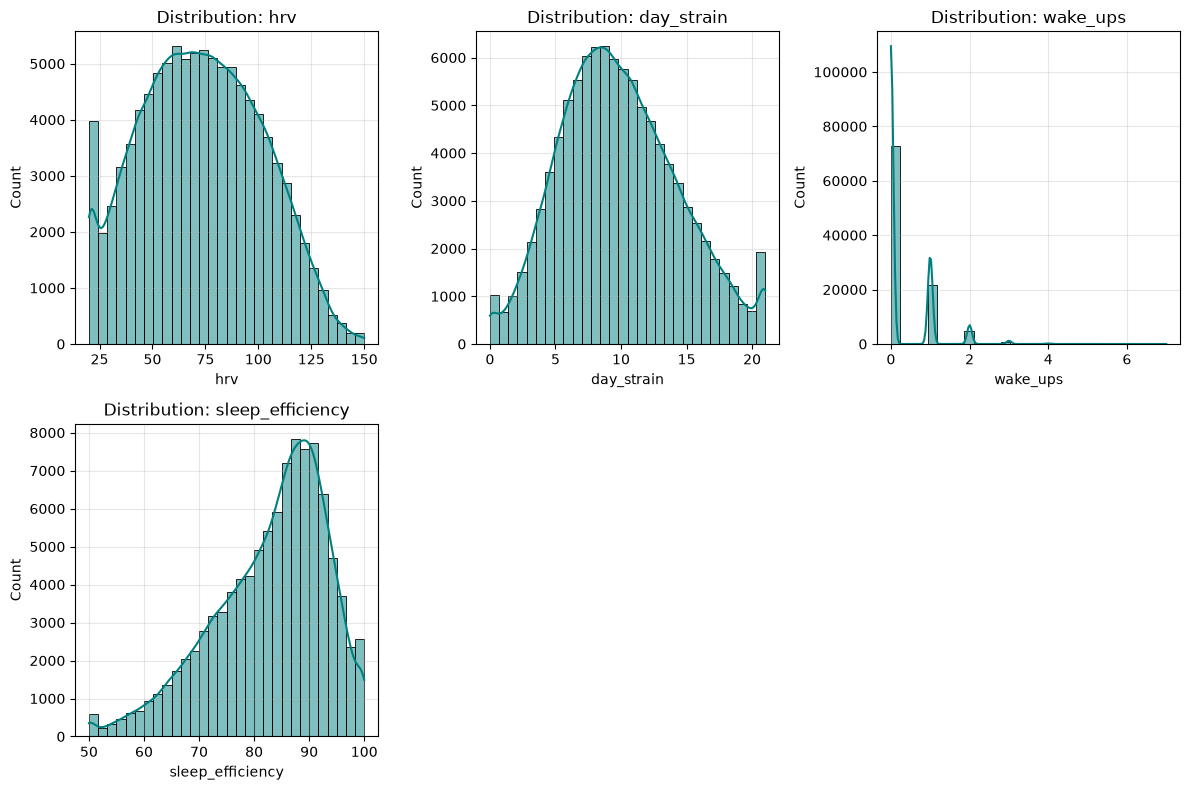

--- Target Consequent Percentile Calibration ---


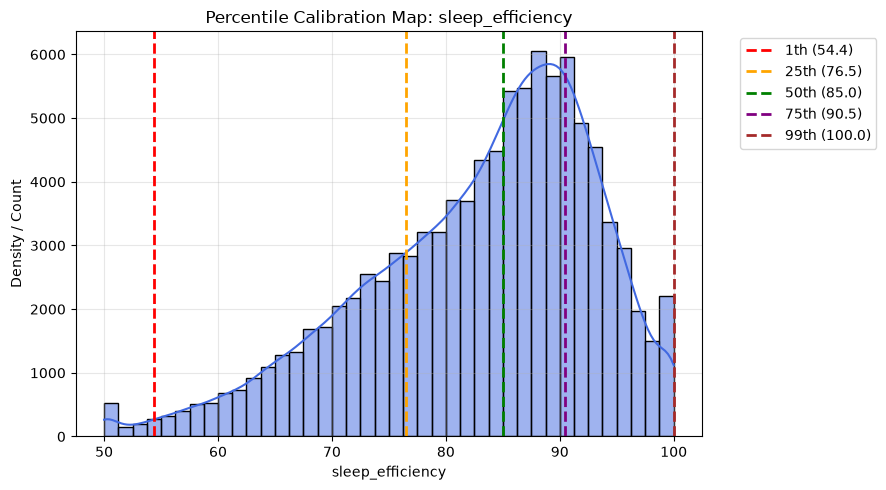

In [3]:
# Extract statistical bounds and percentiles from the real-world dataset
hrv_min, hrv_max = float(df_clean['hrv'].min()), float(df_clean['hrv'].max())
strain_min, strain_max = float(df_clean['day_strain'].min()), float(
    df_clean['day_strain'].max()
)
wake_min, wake_max = int(df_clean['wake_ups'].min()), int(
    df_clean['wake_ups'].max()
)

# Sleep efficiency concentration analysis (handles dense high-bracket skew ~70-95%)
eff_min = max(
    40.0, float(df_clean['sleep_efficiency'].quantile(0.01))
)  # Lower bound trim
eff_q1 = float(df_clean['sleep_efficiency'].quantile(0.25))
eff_median = float(df_clean['sleep_efficiency'].quantile(0.50))
eff_q3 = float(df_clean['sleep_efficiency'].quantile(0.75))
eff_max = float(df_clean['sleep_efficiency'].max())

print(f'HRV Universe: [{hrv_min}, {hrv_max}]')
print(f'Day Strain Universe: [{strain_min}, {strain_max}]')
print(f'Wake-ups Universe: [{wake_min}, {wake_max}]')
print(
    f'Sleep Efficiency Percentiles -> Min: {eff_min}, Q1: {eff_q1}, Median:'
    f' {eff_median}, Q3: {eff_q3}, Max: {eff_max}'
)

# Inspect overall distributions for all input features and target
print('--- Feature Distributions Analysis ---')
plot_data_distributions(
    df_clean, columns=['hrv', 'day_strain', 'wake_ups', 'sleep_efficiency']
)

# Inspect percentile breakdowns specifically for your target output universe calibration
print('--- Target Consequent Percentile Calibration ---')
plot_universe_percentiles(
    df_clean,
    target_col='sleep_efficiency',
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99],
)

## Mamdani FIS Configuration & Membership Functions

--- Generare Grafice Funcții de Apartenență (Antecedente) ---


c:\Users\david\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


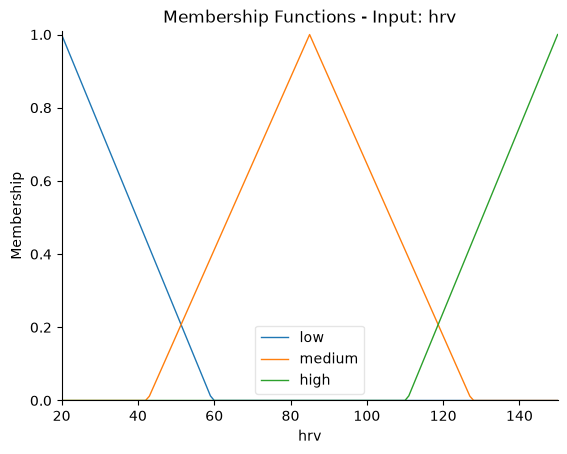

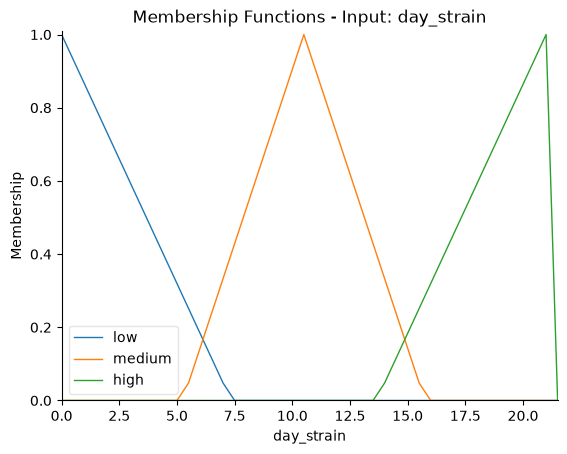

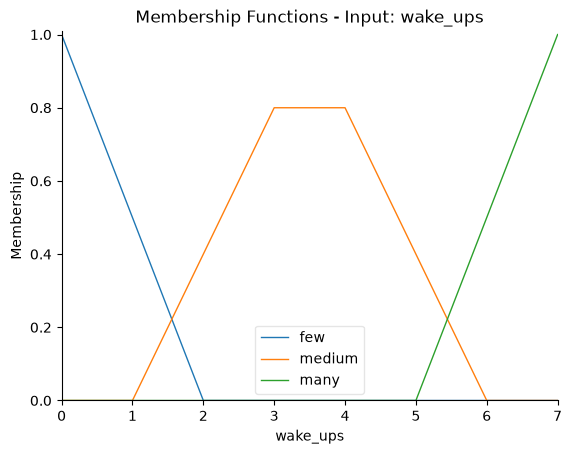

--- Generare Grafice Funcții de Apartenență (Consecvent) ---


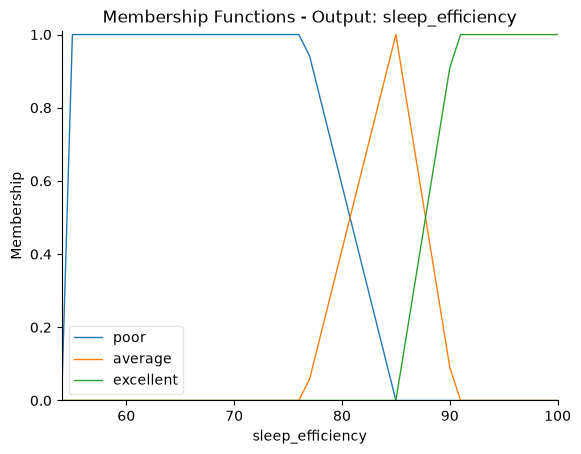

In [4]:
# Instantiate Mamdani Engine
fis = GenericMamdaniEngine()

# Define Antecedents (Inputs) calibrated to real-world dataset bounds
fis.add_antecedent(
    'hrv',
    np.arange(int(hrv_min), int(hrv_max) + 1, 1),
    {
        'low': [hrv_min, hrv_min, (hrv_min + hrv_max) * 0.35],
        'medium': [
            (hrv_min + hrv_max) * 0.25,
            (hrv_min + hrv_max) * 0.5,
            (hrv_min + hrv_max) * 0.75,
        ],
        'high': [(hrv_min + hrv_max) * 0.65, hrv_max, hrv_max],
    },
)

fis.add_antecedent(
    'day_strain',
    np.arange(int(strain_min), int(strain_max) + 1, 0.5),
    {
        'low': [strain_min, strain_min, (strain_min + strain_max) * 0.35],
        'medium': [
            (strain_min + strain_max) * 0.25,
            (strain_min + strain_max) * 0.5,
            (strain_min + strain_max) * 0.75,
        ],
        'high': [(strain_min + strain_max) * 0.65, strain_max, strain_max],
    },
)

fis.add_antecedent(
    'wake_ups',
    np.arange(wake_min, wake_max + 1, 1),
    {
        'few': [wake_min, wake_min, wake_min + 2],
        'medium': [max(wake_min, wake_min + 1), (wake_min + wake_max) / 2, min(wake_max, wake_max - 1)],
        'many': [wake_max - 2, wake_max, wake_max],
    },
)

# Define Consequent (Output) mapped directly to data percentiles to eliminate dead zones
fis.add_consequent(
    'sleep_efficiency',
    np.arange(int(eff_min), int(eff_max) + 1, 1),
    {
        'poor': [eff_min, eff_min, eff_q1, eff_median],
        'average': [eff_q1, eff_median, eff_q3],
        'excellent': [eff_median, eff_q3, eff_max, eff_max],
    },
)

# Visualize Membership Functions
plot_membership_functions(fis)

## IF-THEN Rules Definition

In [ ]:
# # Definition of all 27 IF-THEN Rules (Complete combinatorial rule base)
# ant = fis.antecedents
# cons = fis.consequents

# # single rule system
# rules = [
#     # HRV = Low
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
#     # HRV = Medium
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
#     # HRV = High
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor'])
# ]

# # Build control system with all 27 rules
# fis.build_system(rules)
# print(f"Mamdani control system successfully built with {len(rules)} rules!")

Mamdani control system successfully built with 27 rules!


In [5]:
ant = fis.antecedents
cons = fis.consequents

# Biologically accurate 3D rule matrix sliced by Wake-ups
rule_matrix = {
    'few': {                  # 1st level key: Wake-ups
        'low':    {           # 2nd level key: HRV
            'low': 'average', # 3rd level key: Day Strain -> Consequent
            'medium': 'average', 
            'high': 'average'},
        'medium': {'low': 'average', 'medium': 'average', 'high': 'average'},
        'high':   {'low': 'excellent', 'medium': 'excellent', 'high': 'excellent'}
    },
    'medium': {
        'low':    {'low': 'poor',    'medium': 'poor',    'high': 'poor'},
        'medium': {'low': 'average', 'medium': 'average', 'high': 'poor'},
        'high':   {'low': 'average', 'medium': 'average', 'high': 'average'}
    },
    'many': {
        'low':    {'low': 'poor',    'medium': 'poor',    'high': 'poor'},
        'medium': {'low': 'poor',    'medium': 'poor',    'high': 'poor'},
        'high':   {'low': 'poor',    'medium': 'poor',    'high': 'poor'}
    }
}

# Rules list from the updated matrix
rules = []
table_data = []

rule_count = 1
for wake_level, hrv_dict in rule_matrix.items():
    for hrv_level, strain_dict in hrv_dict.items():
        for strain_level, outcome in strain_dict.items():
            # Create and store the actual rule object for the code
            rule = Rule(
                ant['hrv'][hrv_level] & ant['day_strain'][strain_level] & ant['wake_ups'][wake_level], 
                cons['sleep_efficiency'][outcome]
            )
            rules.append(rule)
            
            # Collect data for the dataframe
            table_data.append({
                "Rule": rule_count,
                "HRV": hrv_level,
                "Day Strain": strain_level,
                "Wake-ups": wake_level,
                "Sleep Efficiency (Consequent)": outcome
            })
            rule_count += 1

df = pd.DataFrame(table_data)
# Permite afișarea tuturor rândurilor în tabelul interactiv
pd.set_option('display.max_rows', None)

# Copies the table to clipboard for word! -> select text -> insert table -> convert text to table -> separate text at Tabs
# df.to_clipboard(index=False, sep='\t')

# Build control system with all 27 rules
fis.build_system(rules)
print(f"Mamdani control system successfully built with {len(rules)} rules!")

# Afișează tabelul interactiv complet (fără print)
df

Mamdani control system successfully built with 27 rules!


,Rule,HRV,Day Strain,Wake-ups,Sleep Efficiency (Consequent)
0,1,low,low,few,average
1,2,low,medium,few,average
2,3,low,high,few,average
3,4,medium,low,few,average
4,5,medium,medium,few,average
5,6,medium,high,few,average
6,7,high,low,few,excellent
7,8,high,medium,few,excellent
8,9,high,high,few,excellent
9,10,low,low,medium,poor


## Running Inference on Dataset

In [6]:
# Run Inference on a sample of the clean dataset
df_sample = df_clean.head(500).copy()
input_features = ['hrv', 'day_strain', 'wake_ups']

print("Running fuzzy inference on dataset...")
y_pred = fis.predict_dataset(df_sample, input_features)
y_true = df_sample['sleep_efficiency'].values

# Filter out potential NaNs
valid_idx = ~np.isnan(y_pred)
y_true_clean = y_true[valid_idx]
y_pred_clean = y_pred[valid_idx]

print(f"Inference complete for {len(y_pred_clean)} valid samples.")

Running fuzzy inference on dataset...
Inference complete for 500 valid samples.


## Evaluation and Visualization

--- Quantitative Error Metrics Table ---


,Metric,Value
0,MAE (Mean Absolute Error),14.993363
1,MSE (Mean Squared Error),307.698903
2,RMSE (Root Mean Squared Error),17.541348
3,R2 Score,-1.974157


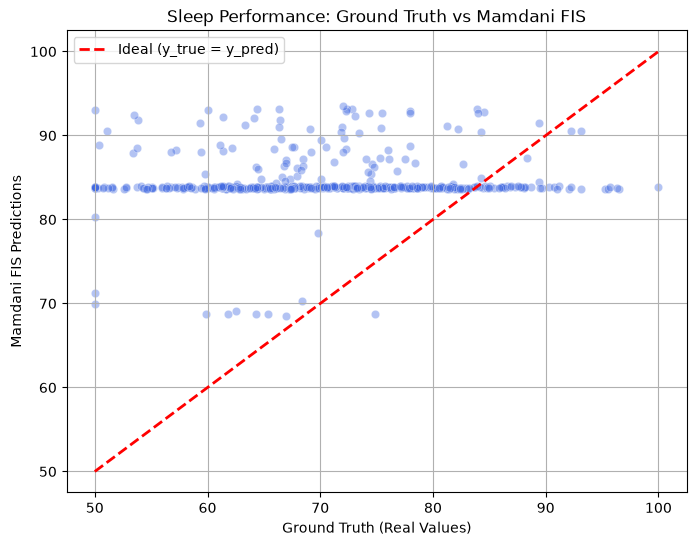

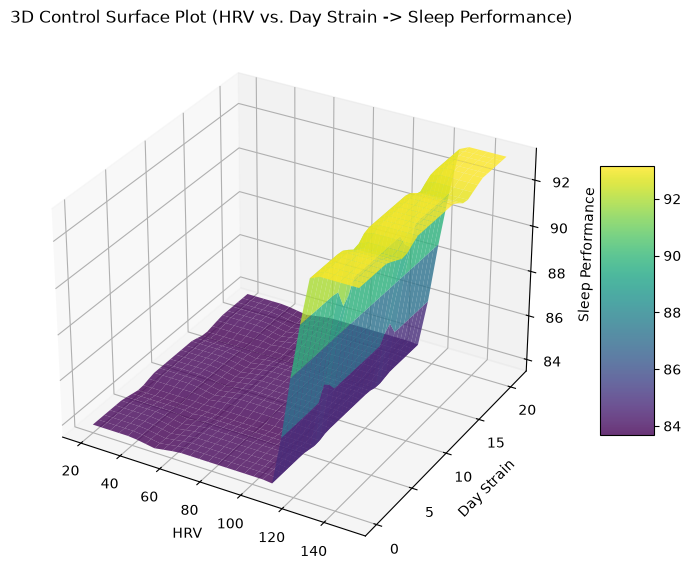

In [7]:
# 1. Quantitative Error Table
metrics_df = evaluate_regression(y_true_clean, y_pred_clean)
print("--- Quantitative Error Metrics Table ---")
display(metrics_df)

# 2. Regression Scatter Plot (Real vs Predicted)
plot_regression_results(y_true_clean, y_pred_clean, title='Sleep Performance: Ground Truth vs Mamdani FIS')

# 3. 3D Control Surface Plot
plot_control_surface(fis.simulation, 'hrv', 'day_strain', 'sleep_efficiency')